In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.transform import resize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


### Datos de entrada

Este modelo se entrenó utilizando imágenes de DBT previamente procesadas y almacenadas en formato `.npy`.

Los archivos de imágenes deben ubicarse en `datos_dbt/Imagenes/` y las etiquetas en `datos_dbt/Etiquetas/`.

Para el entrenamiento y la evaluación, las imágenes se redimensionan a 224 × 224 píxeles y se transforman en vectores unidimensionales.

Los resultados mostrados corresponden a la ejecución experimental original. Su reproducción exacta requiere los mismos conjuntos de datos y condiciones de ejecución.

In [ ]:

# ==========================================
# 1. CONFIGURACIÓN DE RUTAS
# ==========================================

from pathlib import Path

# Carpeta donde se encuentran los datos originales
DATA_DIR = Path("./datos_dbt")

DATA_DIR1 = DATA_DIR / "Imagenes"
DATA_DIR2 = DATA_DIR / "Etiquetas"

# Carpeta para guardar resultados
CKPT_DIR = DATA_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. CARGA DE DATASETS
# ==========================================

print("\n=== Cargando datasets ===")

X_train = np.load(os.path.join(DATA_DIR1, 'X_train_3a1.npy'))
y_train = np.load(os.path.join(DATA_DIR2, 'y_train_3a1.npy'))

X_val = np.load(os.path.join(DATA_DIR1, 'X_val_3a1.npy'))
y_val = np.load(os.path.join(DATA_DIR2, 'y_val_3a1.npy'))

X_test = np.load(os.path.join(DATA_DIR1, 'X_test_3a1.npy'))
y_test = np.load(os.path.join(DATA_DIR2, 'y_test_3a1.npy'))

print("\nTrain:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

print("\nDistribución entrenamiento:")
print(np.bincount(y_train))

print("\nDistribución validación:")
print(np.bincount(y_val))

print("\nDistribución test:")
print(np.bincount(y_test))



=== Cargando datasets ===

Train: (2904, 512, 512, 1)
Val  : (334, 512, 512, 1)
Test : (334, 512, 512, 1)

Distribución entrenamiento:
[2178  726]

Distribución validación:
[250  84]

Distribución test:
[251  83]


In [ ]:
# ==========================================
# 3. PREPROCESAMIENTO KNN
# ==========================================

def resize_dataset(X, size=(224, 224)):
    return np.array([
        resize(img, size, anti_aliasing=True).flatten()
        for img in X
    ])

print("\n=== Preprocesando imágenes ===")

X_train_small = resize_dataset(X_train)
X_val_small = resize_dataset(X_val)
X_test_small = resize_dataset(X_test)

print("Train:", X_train_small.shape)
print("Val  :", X_val_small.shape)
print("Test :", X_test_small.shape)

# ==========================================
# 4. ENTRENAMIENTO KNN
# ==========================================

print("\n=== Entrenando KNN ===")

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train_small, y_train)



=== Preprocesando imágenes ===
Train: (2904, 50176)
Val  : (334, 50176)
Test : (334, 50176)

=== Entrenando KNN ===


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None



=== RESULTADOS KNN - TEST ===
Accuracy      : 0.6317
Sensibilidad  : 0.2892
Especificidad : 0.7450
Precision     : 0.2727
F1-score      : 0.2807
AUC           : 0.5171

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

           0       0.76      0.75      0.75       251
           1       0.27      0.29      0.28        83

    accuracy                           0.63       334
   macro avg       0.52      0.52      0.52       334
weighted avg       0.64      0.63      0.64       334



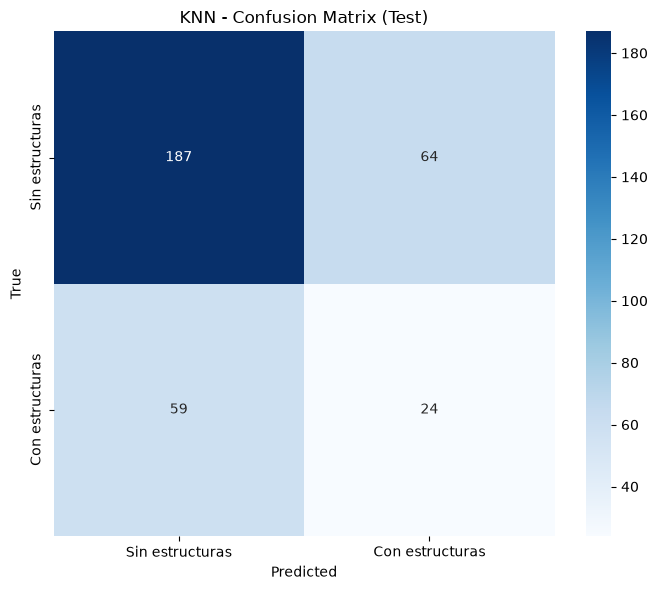

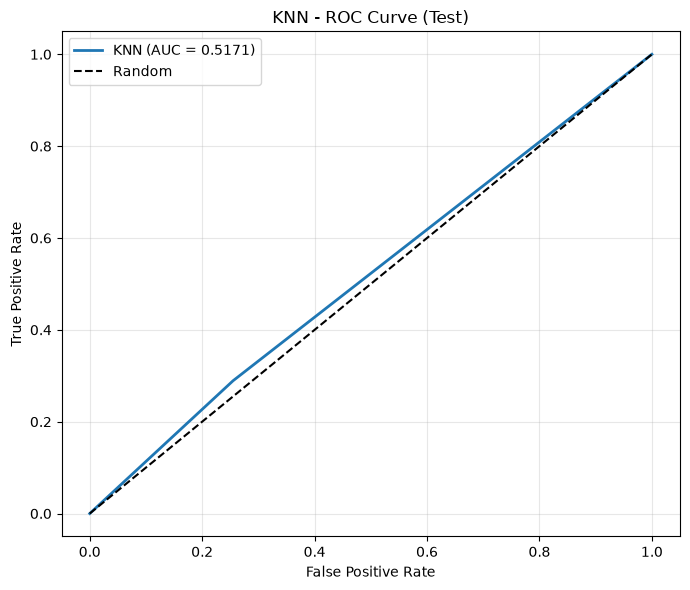

In [ ]:
# ==========================================
# 5. EVALUACIÓN EN TEST
# ==========================================

y_pred = knn.predict(X_test_small)
y_prob = knn.predict_proba(X_test_small)[:, 1]

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)
sensibilidad = recall_score(y_test, y_pred, pos_label=1)
especificidad = tn / (tn + fp)
precision = precision_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print("\n=== RESULTADOS KNN - TEST ===")
print(f"Accuracy      : {accuracy:.4f}")
print(f"Sensibilidad  : {sensibilidad:.4f}")
print(f"Especificidad : {especificidad:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"AUC           : {auc:.4f}")

print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(classification_report(y_test, y_pred, zero_division=0))

# ==========================================
# 6. MATRIZ DE CONFUSIÓN
# ==========================================

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Sin estructuras", "Con estructuras"],
    yticklabels=["Sin estructuras", "Con estructuras"]
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("KNN - Confusion Matrix (Test)")
plt.tight_layout()

plt.savefig(
    os.path.join(CKPT_DIR, "KNN_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. CURVA ROC
# ==========================================

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr, tpr,
    linewidth=2,
    label=f"KNN (AUC = {auc:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN - ROC Curve (Test)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(CKPT_DIR, "KNN_ROC.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
